# Chapter 1: Setting Up Your Visualization Environment

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 1.3 Your First Chart

### Checking the installation

In [1]:
import matplotlib
import seaborn as sns
import plotly
import pandas as pd

print('matplotlib', matplotlib.__version__)
print('seaborn', sns.__version__)
print('plotly', plotly.__version__)
print('pandas', pd.__version__)

matplotlib 3.11.2
seaborn 0.13.2
plotly 7.1.0
pandas 3.0.6


### `plt.plot()`

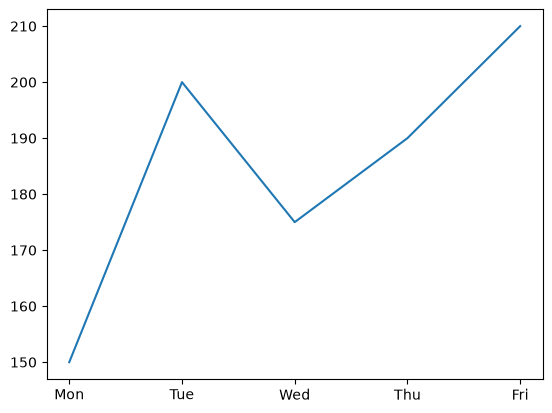

In [2]:
import matplotlib.pyplot as plt
plt.plot(['Mon', 'Tue', 'Wed', 'Thu', 'Fri'], [150, 200, 175, 190, 210])
plt.show()

### `plt.style.use()`

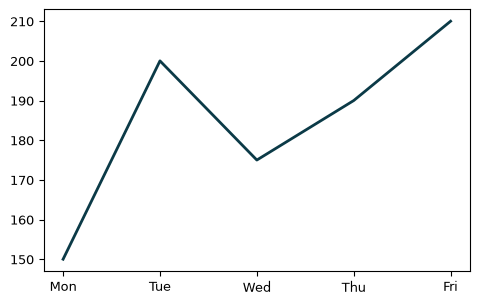

In [3]:
plt.style.use('book.mplstyle')
plt.plot(['Mon', 'Tue', 'Wed', 'Thu', 'Fri'], [150, 200, 175, 190, 210])
plt.show()

## 1.4 A Quick pandas Recap

### `pd.read_csv()`

In [4]:
orders = pd.read_csv('orders_clean.csv', parse_dates=['order_date'])
orders.shape

(184, 8)

### Selecting columns

In [5]:
orders[['order_date', 'product', 'city', 'revenue']].head()

,order_date,product,city,revenue
0,2025-03-08,Webcam,Los Angeles,1295.0
1,2025-03-22,Webcam,Philadelphia,518.0
2,2025-04-15,USB Cable,San Francisco,59.7
3,2025-05-01,Monitor,Los Angeles,4396.0
4,2025-01-16,Headset,New York,189.0


### Filtering rows

In [6]:
big_seattle = orders[(orders['city'] == 'Seattle')
                     & (orders['revenue'] > 500)]
big_seattle[['order_date', 'product', 'revenue']]

,order_date,product,revenue
8,2025-03-30,Headset,567.0
12,2025-05-27,Webcam,1036.0
38,2025-01-18,Webcam,518.0
56,2025-01-29,Webcam,1036.0
68,2025-01-11,Headset,945.0
142,2025-06-04,Keyboard,645.0
157,2025-02-06,Webcam,518.0


### `df.sort_values()`

In [7]:
orders.sort_values('revenue', ascending=False)[
    ['product', 'quantity', 'revenue']].head(3)

,product,quantity,revenue
43,Monitor,5,5495.0
92,Monitor,5,5495.0
171,Monitor,5,5495.0


### `df.groupby()`

In [8]:
city_revenue = orders.groupby('city')['revenue'].sum()
city_revenue

city
Denver            4898.1
Los Angeles      24692.7
New York         53508.5
Philadelphia     25663.9
San Francisco    13747.4
Seattle           6250.5
Unknown          13047.5
Name: revenue, dtype: float64

### `s.value_counts()`

In [9]:
orders['product'].value_counts()

product
Webcam       42
USB Cable    37
Headset      29
Keyboard     27
Mouse        26
Monitor      23
Name: count, dtype: int64

### More table tools

In [10]:
two_cities = orders[orders['city'].isin(['Denver', 'Seattle'])]
two_cities['city'].value_counts()

city
Seattle    14
Denver     14
Name: count, dtype: int64

In [11]:
by_city = city_revenue.reset_index()
by_city.head(3)

,city,revenue
0,Denver,4898.1
1,Los Angeles,24692.7
2,New York,53508.5


In [12]:
orders.loc[orders['revenue'] > 5000, ['product', 'revenue']]

,product,revenue
43,Monitor,5495.0
92,Monitor,5495.0
95,Monitor,5495.0
96,Monitor,5495.0
98,Monitor,5495.0
161,Monitor,5495.0
171,Monitor,5495.0


In [13]:
orders.iloc[0:2, 0:3]

,order_id,order_date,product
0,ORD-1001,2025-03-08,Webcam
1,ORD-1003,2025-03-22,Webcam


In [14]:
orders.pivot_table(index='product', columns='segment',
                   values='revenue', aggfunc='sum')

segment,Business,Consumer,Unknown
product,,,
Headset,4725.0,6615.0,567.0
Keyboard,903.0,9546.0,NaN
Monitor,16485.0,68138.0,NaN
Mouse,698.6,2894.2,NaN
USB Cable,398.0,1731.3,99.5
Webcam,5439.0,23569.0,NaN


### The Python you'll meet

In [15]:
colors = {'Online': '#0b3a47', 'In store': '#b26a00'}
colors['Online']

'#0b3a47'

In [16]:
for city in ['Denver', 'Seattle']:
    print(city, city_revenue[city])

Denver 4898.1
Seattle 6250.5


In [17]:
total = orders['revenue'].sum()
print(f'Total revenue: ${total:,.0f}')

Total revenue: $141,809


In [18]:
amounts = [120, 640, 85]
['big' if a > 100 else 'small' for a in amounts]

['big', 'big', 'small']

### From a table to a chart

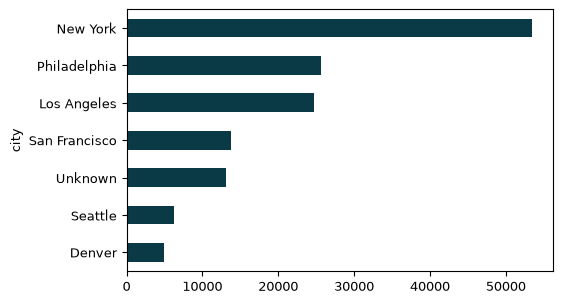

In [19]:
city_revenue.sort_values().plot.barh()
plt.show()

## 1.5 When Something Doesn't Work

### A library that isn't installed

Shown in the book but not run here:

```python
import seaborn as sns
```

### A data file that can't be found

The next cell raises an error on purpose.

In [20]:
pd.read_csv('orders.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'orders.csv'

### A style file that can't be found

Shown in the book but not run here:

```python
plt.style.use('book_style.mplstyle')
```